# features-alpha demo
Compute price factors, check they have **no look-ahead**, and measure their IC against 21-day forward returns. Synthetic data has a planted momentum effect, so momentum should show a positive IC.

In [1]:
import pandas as pd

from quantskills.data import synthetic_prices, to_wide
from quantskills.eval import ic_summary, information_coefficient, quantile_returns
from quantskills.features import compute_factors, forward_returns
from quantskills.utils import assert_no_lookahead

close = to_wide(synthetic_prices(n_assets=40, n_days=1260, seed=0))
from quantskills.features import FACTORS

factors = compute_factors(close)
for _name, fn in FACTORS.items():
    assert_no_lookahead(fn, close)
print("no look-ahead in", list(FACTORS))

no look-ahead in ['momentum', 'reversal', 'low_vol']


In [2]:
fwd = forward_returns(close, 21)  # LABEL: shifted forward, never a feature
report = pd.DataFrame(
    {n: ic_summary(information_coefficient(f, fwd), horizon=21) for n, f in factors.items()}
).T
report.round(3)

,mean_ic,ic_std,ic_ir,t_stat,hit_rate,n_obs
momentum,0.040,0.155,0.258,1.435,0.597,47.0
reversal,0.036,0.167,0.216,1.900,0.613,58.0
low_vol,-0.007,0.184,-0.039,-0.037,0.457,56.0


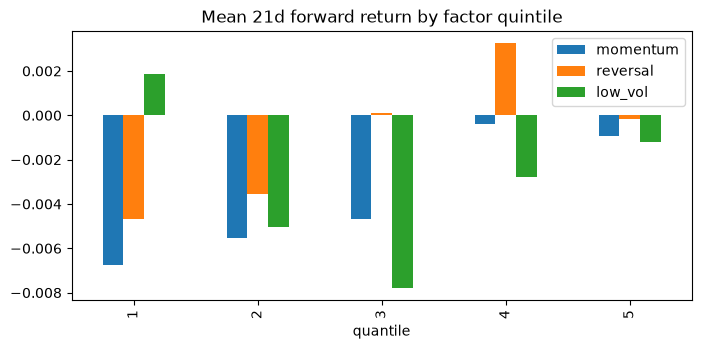

In [3]:
q = pd.DataFrame({n: quantile_returns(f, fwd) for n, f in factors.items()})
q.plot.bar(figsize=(8, 3.5), title="Mean 21d forward return by factor quintile");